## Step 1: Loading & First Inspection
In this step, we import the core data science libraries, load the raw dataset from `data/raw/`, inspect the dimensions (rows/columns), preview sample records, and verify column data types.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 
import seaborn as sns

df = pd.read_csv("../src/data/student_mental_health.csv")

df.head()

,Student_ID,Age,Gender,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Physical_Activity,Financial_Stress,Family_Support,Attendance_Rate,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Mental_Health_Risk
0,STU0001,22,Male,3,6.6,17.6,2.91,6.9,7.5,Moderate,8.5,4.0,78.0,No,Poor,No,High
1,STU0002,21,Male,4,5.6,22.4,2.92,7.6,11.5,Low,4.5,5.3,85.4,Yes,Average,No,Medium
2,STU0003,22,Male,5,7.1,28.1,2.68,6.5,8.9,Low,4.8,6.1,79.5,No,Average,No,Medium
3,STU0004,24,Male,1,4.5,14.8,2.23,5.5,7.6,High,3.7,8.0,73.9,No,Average,Yes,High
4,STU0005,20,Female,1,6.7,17.2,2.69,4.3,7.0,Moderate,8.0,7.4,99.8,Yes,NaN,No,Medium


In [5]:
df.shape

(2000, 17)

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Student_ID                      2000 non-null   str    
 1   Age                             2000 non-null   int64  
 2   Gender                          2000 non-null   str    
 3   Year_of_Study                   2000 non-null   int64  
 4   Sleep_Hours                     1938 non-null   float64
 5   Study_Hours_Per_Week            2000 non-null   float64
 6   GPA                             1962 non-null   float64
 7   Social_Media_Hours              1942 non-null   float64
 8   Screen_Time_Hours               2000 non-null   float64
 9   Physical_Activity               2000 non-null   str    
 10  Financial_Stress                1909 non-null   float64
 11  Family_Support                  1946 non-null   float64
 12  Attendance_Rate                 1953 non-null

In [25]:
df.describe()

,Age,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Financial_Stress,Family_Support,Attendance_Rate
count,2000.000000,2000.000000,1938.000000,2000.000000,1962.000000,1942.000000,2000.000000,1909.000000,1946.000000,1953.000000
mean,21.131500,2.630000,6.758875,19.997900,2.562503,6.013955,8.548500,5.956260,6.518345,85.080236
std,2.139275,1.316802,1.127072,5.719274,0.343993,1.153422,1.657571,1.893941,1.844639,7.224118
min,17.000000,1.000000,3.300000,2.400000,1.500000,2.100000,3.300000,1.400000,1.700000,54.400000
25%,20.000000,1.000000,6.000000,16.000000,2.320000,5.225000,7.400000,4.500000,5.100000,80.300000
50%,21.000000,2.000000,6.700000,19.800000,2.560000,6.000000,8.500000,6.100000,6.700000,85.100000
75%,23.000000,4.000000,7.600000,24.000000,2.790000,6.700000,9.700000,7.400000,8.000000,90.000000
max,29.000000,5.000000,10.000000,38.300000,3.660000,10.000000,14.000000,10.000000,9.900000,100.000000


# Exploratory Data Analysis (EDA)

Check data quality before building our models.

In [16]:
display(pd.DataFrame({
    "Missing ": df.isnull().sum(),
    "Precentage" : (df.isnull().mean() * 100).round(2)
}))

# duuplicates 
print("duuplicated roows :" , df.duplicated().sum())

# uniique

display(df.nunique().to_frame("Unique Values"))

,Missing,Precentage
Student_ID,0,0.00
Age,0,0.00
Gender,0,0.00
Year_of_Study,0,0.00
Sleep_Hours,62,3.10
Study_Hours_Per_Week,0,0.00
GPA,38,1.90
Social_Media_Hours,58,2.90
Screen_Time_Hours,0,0.00
Physical_Activity,0,0.00


duuplicated roows : 0


,Unique Values
Student_ID,2000
Age,13
Gender,3
Year_of_Study,5
Sleep_Hours,66
Study_Hours_Per_Week,284
GPA,182
Social_Media_Hours,71
Screen_Time_Hours,95
Physical_Activity,3


## 2. Descriptive Statistics

Explore numerical and categorical columns to understand their values and distributions.

In [19]:
print(df["Student_ID"].dtype)
print(df.select_dtypes(include=np.number).columns.tolist())

str
['Age', 'Year_of_Study', 'Sleep_Hours', 'Study_Hours_Per_Week', 'GPA', 'Social_Media_Hours', 'Screen_Time_Hours', 'Financial_Stress', 'Family_Support', 'Attendance_Rate']


In [23]:
numeric_columns = df.select_dtypes(include=np.number).columns.drop("Student_ID",errors="ignore")

display(df[numeric_columns].describe().T)

,count,mean,std,min,25%,50%,75%,max
Age,2000.0,21.131500,2.139275,17.0,20.000,21.00,23.00,29.00
Year_of_Study,2000.0,2.630000,1.316802,1.0,1.000,2.00,4.00,5.00
Sleep_Hours,1938.0,6.758875,1.127072,3.3,6.000,6.70,7.60,10.00
Study_Hours_Per_Week,2000.0,19.997900,5.719274,2.4,16.000,19.80,24.00,38.30
GPA,1962.0,2.562503,0.343993,1.5,2.320,2.56,2.79,3.66
Social_Media_Hours,1942.0,6.013955,1.153422,2.1,5.225,6.00,6.70,10.00
Screen_Time_Hours,2000.0,8.548500,1.657571,3.3,7.400,8.50,9.70,14.00
Financial_Stress,1909.0,5.956260,1.893941,1.4,4.500,6.10,7.40,10.00
Family_Support,1946.0,6.518345,1.844639,1.7,5.100,6.70,8.00,9.90
Attendance_Rate,1953.0,85.080236,7.224118,54.4,80.300,85.10,90.00,100.00


In [24]:
categorrical_cols = df.select_dtypes(include="object").columns

display(df[categorrical_cols].describe().T)

/tmp/ipykernel_850349/2778497599.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorrical_cols = df.select_dtypes(include="object").columns


,count,unique,top,freq
Student_ID,2000,2000,STU0001,1
Gender,2000,3,Female,971
Physical_Activity,2000,3,Moderate,906
Part_Time_Job,2000,2,No,1289
Diet_Quality,1931,3,Average,860
Previous_Mental_Health_History,2000,2,No,1408
Mental_Health_Risk,2000,3,High,680


## 3. Target Distribution

Analyze the distribution of the target variable and check for class imbalance.

In [26]:
target_counts = df["Mental_Health_Risk"].value_counts()

display(target_counts)

Mental_Health_Risk
High      680
Medium    660
Low       660
Name: count, dtype: int64

In [27]:
target_percentages = df["Mental_Health_Risk"].value_counts(normalize=True) * 100

display(target_percentages.round(2))

Mental_Health_Risk
High      34.0
Medium    33.0
Low       33.0
Name: proportion, dtype: float64

### Visualize the number of students in each risk category.

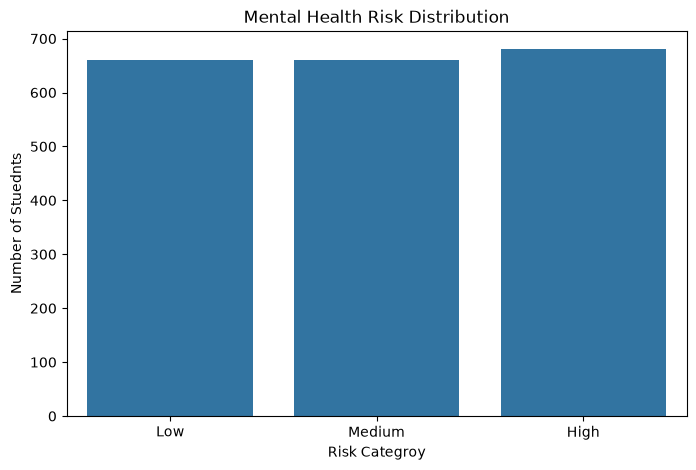

In [29]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Mental_Health_Risk",
    order=["Low", "Medium" , "High"]
)

plt.title("Mental Health Risk Distribution")
plt.xlabel("Risk Categroy")
plt.ylabel("Number of Stuednts")

plt.show()

## 4. Univariate Analysis

Analyze each feature separately to understand its distribution and identify unusual values.

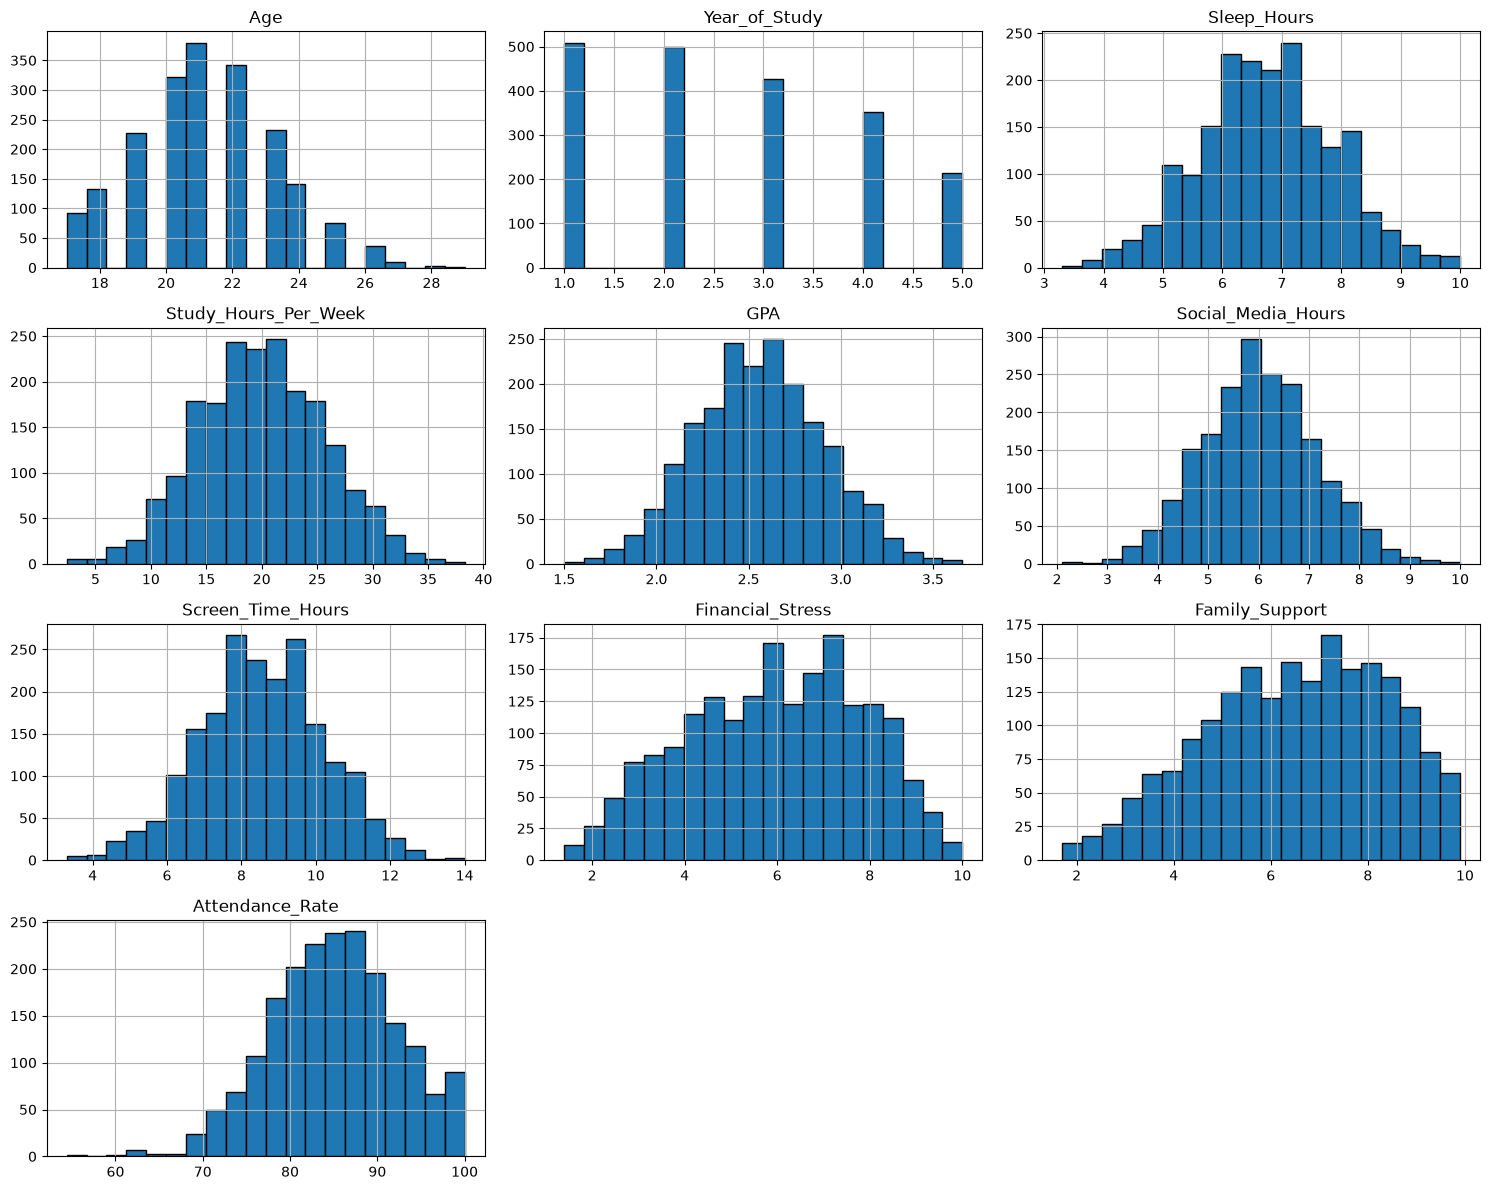

In [30]:
numeric_columns = df.select_dtypes(include=np.number).columns.drop(
    "Student_ID", errors="ignore"
)

df[numeric_columns].hist(
    figsize=(15, 12),
    bins=20,
    edgecolor="black"
)

plt.tight_layout()
plt.show()

### 4.1 Categorical Features

Analyze the frequency of each category using countplots.

/tmp/ipykernel_850349/4280460271.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(include="object").columns.drop(


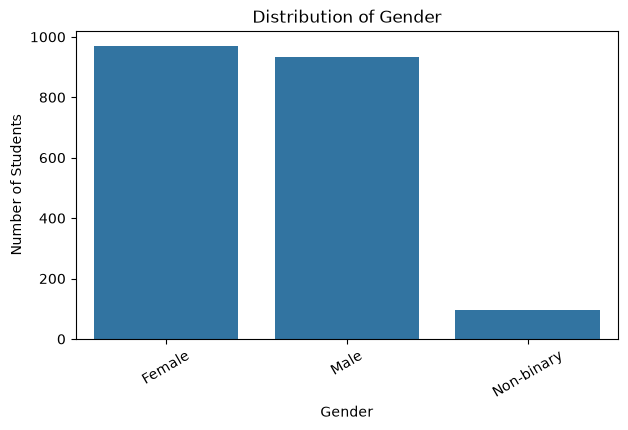

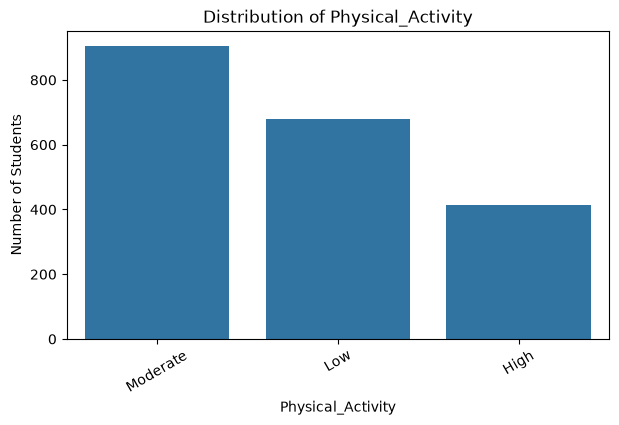

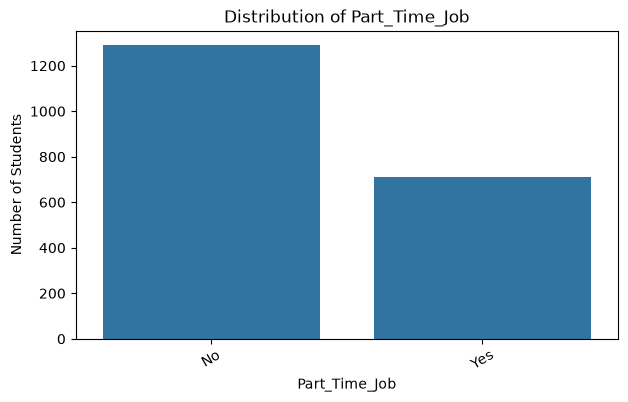

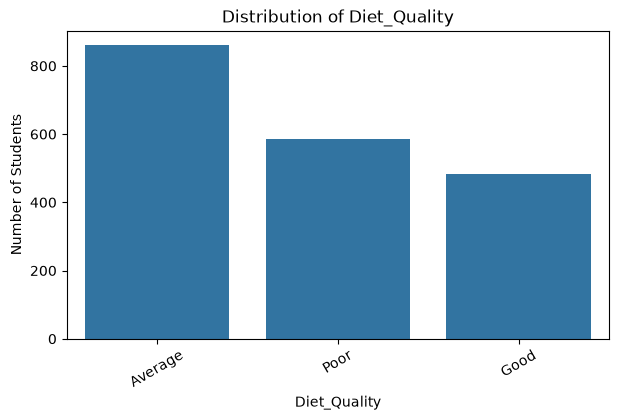

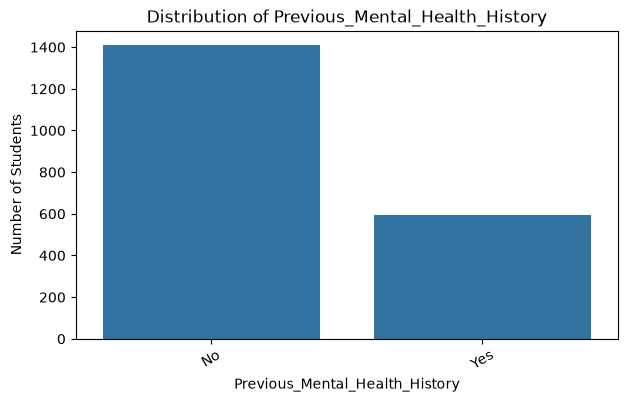

In [31]:
categorical_columns = df.select_dtypes(include="object").columns.drop(
    ["Student_ID", "Mental_Health_Risk"], errors="ignore"
)

for column in categorical_columns:
    plt.figure(figsize=(7, 4))

    sns.countplot(
        data=df,
        x=column,
        order=df[column].value_counts().index
    )

    plt.title(f"Distribution of {column}")
    plt.xlabel(column)
    plt.ylabel("Number of Students")
    plt.xticks(rotation=30)

    plt.show()

In [33]:
for column in categorical_columns:
    print(f"\n--- {column} ---")
    print(df[column].value_counts())
    print("\nPercentages:")
    print(df[column].value_counts(normalize=True).mul(100).round(2))


--- Gender ---
Gender
Female        971
Male          932
Non-binary     97
Name: count, dtype: int64

Percentages:
Gender
Female        48.55
Male          46.60
Non-binary     4.85
Name: proportion, dtype: float64

--- Physical_Activity ---
Physical_Activity
Moderate    906
Low         679
High        415
Name: count, dtype: int64

Percentages:
Physical_Activity
Moderate    45.30
Low         33.95
High        20.75
Name: proportion, dtype: float64

--- Part_Time_Job ---
Part_Time_Job
No     1289
Yes     711
Name: count, dtype: int64

Percentages:
Part_Time_Job
No     64.45
Yes    35.55
Name: proportion, dtype: float64

--- Diet_Quality ---
Diet_Quality
Average    860
Poor       587
Good       484
Name: count, dtype: int64

Percentages:
Diet_Quality
Average    44.54
Poor       30.40
Good       25.06
Name: proportion, dtype: float64

--- Previous_Mental_Health_History ---
Previous_Mental_Health_History
No     1408
Yes     592
Name: count, dtype: int64

Percentages:
Previous_Mental_Hea

In [35]:
for column in categorical_columns:
    print(f"\n{column}")
    display(
        df[column].value_counts(dropna=False).to_frame("Count")
    )


Gender


,Count
Gender,
Female,971
Male,932
Non-binary,97



Physical_Activity


,Count
Physical_Activity,
Moderate,906
Low,679
High,415



Part_Time_Job


,Count
Part_Time_Job,
No,1289
Yes,711



Diet_Quality


,Count
Diet_Quality,
Average,860
Poor,587
Good,484
NaN,69



Previous_Mental_Health_History


,Count
Previous_Mental_Health_History,
No,1408
Yes,592


## 5. Bivariate Analysis

Analyze the relationships between features and the target variable.

In [37]:
pd.crosstab(
    df["Physical_Activity"],
    df["Mental_Health_Risk"],
    normalize="index"
).mul(100).round(2)

Mental_Health_Risk,High,Low,Medium
Physical_Activity,,,
High,20.24,49.40,30.36
Low,45.95,22.83,31.22
Moderate,31.35,33.11,35.54


In [38]:
pd.crosstab(
    df["Gender"],
    df["Mental_Health_Risk"],
    normalize="index"
).mul(100).round(2)

Mental_Health_Risk,High,Low,Medium
Gender,,,
Female,34.60,33.47,31.93
Male,33.37,31.76,34.87
Non-binary,34.02,40.21,25.77


In [39]:
pd.crosstab(
    df["Part_Time_Job"],
    df["Mental_Health_Risk"],
    normalize="index"
).mul(100).round(2)

Mental_Health_Risk,High,Low,Medium
Part_Time_Job,,,
No,30.26,36.23,33.51
Yes,40.79,27.14,32.07


In [40]:
pd.crosstab(
    df["Diet_Quality"],
    df["Mental_Health_Risk"],
    normalize="index"
).mul(100).round(2)

Mental_Health_Risk,High,Low,Medium
Diet_Quality,,,
Average,32.33,33.49,34.19
Good,27.48,42.77,29.75
Poor,42.25,24.02,33.73


In [41]:
pd.crosstab(
    df["Previous_Mental_Health_History"],
    df["Mental_Health_Risk"],
    normalize="index"
).mul(100).round(2)

Mental_Health_Risk,High,Low,Medium
Previous_Mental_Health_History,,,
No,27.41,39.28,33.31
Yes,49.66,18.07,32.26


In [42]:
pd.crosstab(
    df["Year_of_Study"],
    df["Mental_Health_Risk"],
    normalize="index"
).mul(100).round(2)

Mental_Health_Risk,High,Low,Medium
Year_of_Study,,,
1,45.58,25.93,28.49
2,34.00,28.20,37.80
3,28.64,35.68,35.68
4,32.10,38.07,29.83
5,20.19,47.42,32.39


### Numerical Features vs Target

Compare numerical features across the three mental health risk groups using their median values.

In [44]:
df.groupby("Mental_Health_Risk")[numeric_columns].median().T

Mental_Health_Risk,High,Low,Medium
Age,21.00,21.00,21.00
Year_of_Study,2.00,3.00,2.00
Sleep_Hours,6.10,7.60,6.70
Study_Hours_Per_Week,18.00,21.70,20.15
GPA,2.42,2.71,2.54
Social_Media_Hours,6.30,5.80,5.90
Screen_Time_Hours,9.00,8.20,8.40
Financial_Stress,6.90,5.10,6.00
Family_Support,5.90,7.40,6.65
Attendance_Rate,83.85,86.60,85.35


### Correlation Analysis

Analyze the relationships between numerical features using a correlation matrix and heatmap.

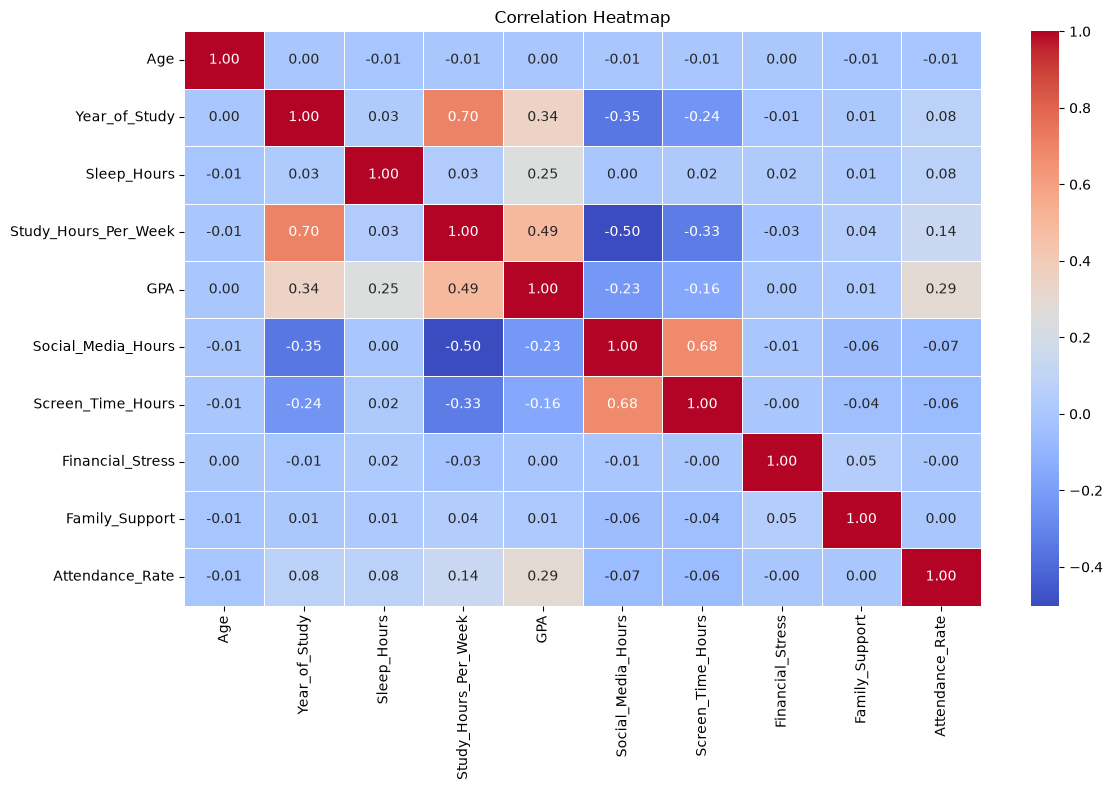

In [47]:
correlation_matrix = df[numeric_columns].corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

### Correlation Analysis

- Strong positive correlation: Year_of_Study and Study_Hours_Per_Week (0.70).
- Strong positive correlation: Social_Media_Hours and Screen_Time_Hours (0.68).
- Moderate negative correlation: Study_Hours_Per_Week and Social_Media_Hours (-0.50).
- Moderate positive correlation: Study_Hours_Per_Week and GPA (0.49).
- Moderate negative correlation: Year_of_Study and Social_Media_Hours (-0.35).



### Outlier Investigation

Boxplots are used to visualize numerical distributions and identify potential outliers. We will use the IQR method to investigate unusual values.

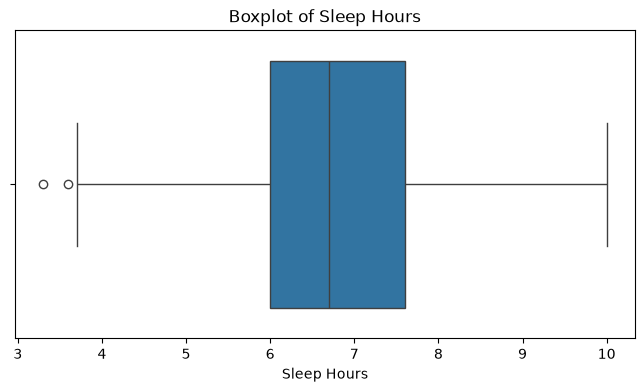

In [55]:
plt.figure(figsize=(8, 4))

sns.boxplot(x=df["Sleep_Hours"])

plt.title("Boxplot of Sleep Hours")
plt.xlabel("Sleep Hours")
plt.show()

### Ccalculate the IQR ourselves

In [49]:
Q1 = df["Sleep_Hours"].quantile(0.25)
Q2 = df["Sleep_Hours"].quantile(0.50)
Q3 = df["Sleep_Hours"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

Q1: 6.0
Q3: 7.6
IQR: 1.5999999999999996
Lower Bound: 3.6000000000000005
Upper Bound: 10.0


In [50]:
outliers = df[
    (df["Sleep_Hours"] < lower_bound) |
    (df["Sleep_Hours"] > upper_bound)
]

print("Number of potential outliers:", len(outliers))

Number of potential outliers: 2


In [51]:
outliers[["Student_ID", "Sleep_Hours"]]

,Student_ID,Sleep_Hours
749,STU0750,3.6
1982,STU1983,3.3


In [52]:
df["Sleep_Hours"].agg(["min", "max"])

min     3.3
max    10.0
Name: Sleep_Hours, dtype: float64

In [53]:
outliers = df[
    (df["Sleep_Hours"] < lower_bound) |
    (df["Sleep_Hours"] > upper_bound)
]

print(outliers[["Student_ID", "Sleep_Hours"]])
print("Number of outliers:", len(outliers))

     Student_ID  Sleep_Hours
749     STU0750          3.6
1982    STU1983          3.3
Number of outliers: 2


In [59]:
outliers_counts = {}

for column in numeric_columns:

    Q1 = df[column].quantile(0.25)
    Q2 = df[column].quantile(0.50)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR


    outliers =df[
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ]

    outliers_counts[column] = len(outliers)
pd.Series(outliers_counts , name="Number of Outliers")

Age                      4
Year_of_Study            0
Sleep_Hours              2
Study_Hours_Per_Week     7
GPA                      9
Social_Media_Hours      20
Screen_Time_Hours        7
Financial_Stress         0
Family_Support           0
Attendance_Rate         12
Name: Number of Outliers, dtype: int64

### Outlier Visualization

Use boxplots to visualize the distribution of numerical features and identify potential outliers.

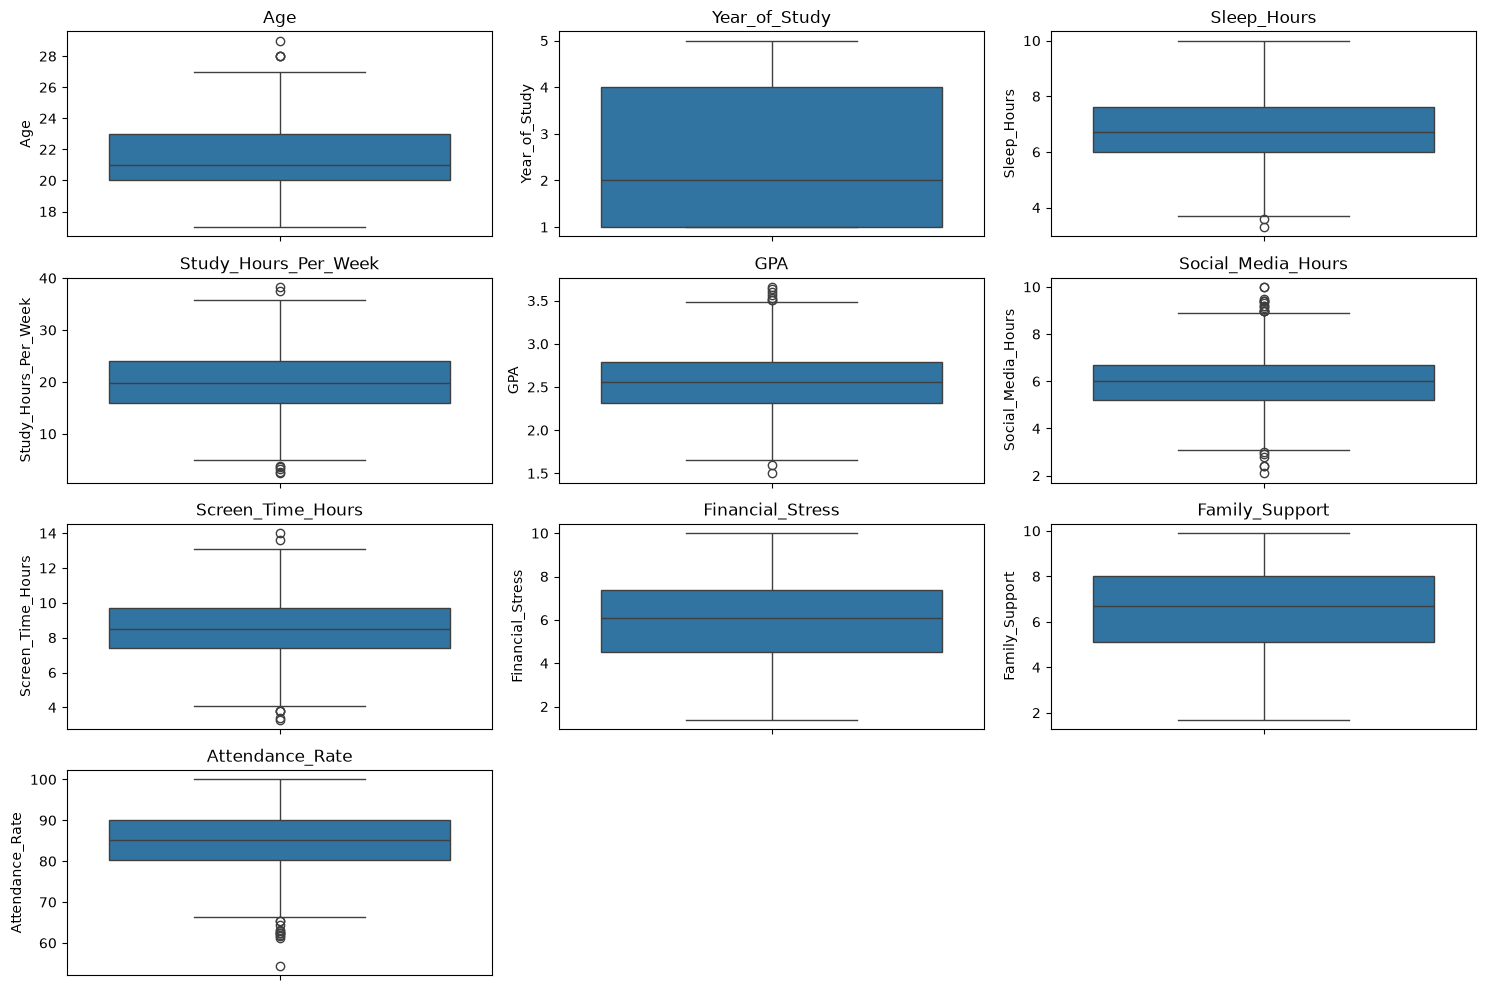

In [60]:
plt.figure(figsize=(15, 10))

for i, column in enumerate(numeric_columns, 1):
    plt.subplot(4, 3, i)
    sns.boxplot(y=df[column])
    plt.title(column)

plt.tight_layout()
plt.show()

### Outlier Analysis

The IQR method identified potential outliers in several numerical features.

- Social_Media_Hours: 20 outliers.
- Attendance_Rate: 12 outliers.
- GPA: 9 outliers.
- Study_Hours_Per_Week: 7 outliers.
- Screen_Time_Hours: 7 outliers.
- Age: 4 outliers.
- Sleep_Hours: 2 outliers.
- Year_of_Study: 0 outliers.
- Financial_Stress: 0 outliers.



In [61]:
correlation_pairs = (
    correlation_matrix.where(
        np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool)
    )
    .stack()
    .sort_values(key=abs, ascending=False)
)

correlation_pairs

Year_of_Study         Study_Hours_Per_Week    0.703401
Social_Media_Hours    Screen_Time_Hours       0.681404
Study_Hours_Per_Week  Social_Media_Hours     -0.501178
                      GPA                     0.492501
Year_of_Study         Social_Media_Hours     -0.353989
                                                ...   
Attendance_Rate       Social_Media_Hours           NaN
                      Screen_Time_Hours            NaN
                      Financial_Stress             NaN
                      Family_Support               NaN
                      Attendance_Rate              NaN
Length: 100, dtype: float64

## EDA Conclusion

- **Dataset:** 2,000 rows and 17 columns.
- **Missing values:** Found in several numerical and categorical features.
- **Duplicates:** No duplicate rows found.
- **Target distribution:** Approximately balanced across High (34%), Medium (33%) and Low (33%) risk.
- **Feature relationships:** Physical activity, previous mental health history, diet quality and financial stress show potential associations with the target.
- **Correlations:** Strong relationships were observed between study year and study hours, and between social media hours and screen time.
- **Outliers:** Potential outliers were identified in several numerical features using the IQR method.

